# Variational (Hardware-Efficient / Heuristic) Ansatz — CUDA-Q

**Primitive:** Heuristic Ansatz (a.k.a. Hardware-Efficient Ansatz) -- same circuit as the
matched Qiskit notebook, built with identical gates, identical qubit indices, and
identical fixed parameters, so the two `_RESULT` dictionaries match after the ordering
fix below is applied.

## SETUP (identical in both notebooks — do not diverge)
- **N_QUBITS** = 2
- **Structure**: 3 rotation blocks (R0, R1, R2) interleaved with 2 entangling blocks (E0, E1)
  - R0: `RY(θ0) RZ(θ1)` on q0, `RY(θ2) RZ(θ3)` on q1
  - E0: `CNOT(control=q0, target=q1)`
  - R1: `RY(θ4) RZ(θ5)` on q0, `RY(θ6) RZ(θ7)` on q1
  - E1: `CNOT(control=q0, target=q1)`
  - R2 (final, no entangler after): `RY(θ8) RZ(θ9)` on q0, `RY(θ10) RZ(θ11)` on q1
- **θ (fixed, radians)** = `[0.30, 0.70, 1.10, 0.40, 0.90, 1.30, 0.50, 0.20, 1.05, 0.85, 0.35, 0.65]`
- **QUBIT ORDERING CONTRACT**: qubit 0 = rightmost bit in every *printed* bitstring
  (Qiskit's convention). CUDA-Q's native `get_state()`/`sample()` index qubit 0 as the
  **leftmost (most-significant)** bit -- this notebook explicitly reverses every
  bitstring so its final printed dictionaries match Qiskit's.
- **SHOTS** = 10000, **SEED** = 42
- **GLOBAL PHASE CONVENTION**: identical function to the Qiskit notebook -- normalize so
  the first amplitude with `abs(amp) > 1e-9`, in ascending *Qiskit-convention* bitstring
  order (`'00'`, `'01'`, `'10'`, `'11'`), is rotated to be real and positive.
- **Basis ordering for matrices**: `{|00>, |01>, |10>, |11>}`, ascending binary order,
  same `q1 q0` (q1=MSB, q0=LSB) convention as the Qiskit notebook, *after* the bit-order
  fix is applied.

## Theory recap
Same gates as the Qiskit notebook:

`RY(θ) = [[cos(θ/2), -sin(θ/2)], [sin(θ/2), cos(θ/2)]]`,
`RZ(θ) = [[e^(-iθ/2), 0], [0, e^(iθ/2)]]`,
`CNOT(q0->q1) = [[1,0,0,0],[0,0,0,1],[0,0,1,0],[0,1,0,0]]` in the `{|00>,|01>,|10>,|11>}` basis.

**Ordering-convention warning:** CUDA-Q's `cudaq.qvector` numbers qubit 0 as the
**most-significant / leftmost** bit in both `get_state()` amplitude indices and
`sample()` bitstrings -- the opposite of Qiskit. The gates below are applied to the
*same physical qubit indices* as the Qiskit notebook (rotation angles and the CNOT
control/target are unchanged), so the underlying physics is identical; only the
*bitstring labels* CUDA-Q prints are reversed relative to Qiskit's convention. The
explicit reversal is done in its own cell below, not hidden inline.

**Run all cells top to bottom.**


In [1]:
# Install cell.
# cudaq: CUDA-Q Python package. CPU-only simulation (used here, 2 qubits) works on any
# supported platform (Linux x86_64/ARM64); GPU acceleration is optional and not required
# for a circuit this small. Requires Python 3.10-3.12 per current CUDA-Q releases.
!pip install -q cudaq

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 MB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 47.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 MB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 81.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 MB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 MB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 64.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 MB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.7/244.7 MB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 MB 7.9 MB/s eta 0:00

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cudaq

# ---- constants (must match the Qiskit notebook exactly) ----
N_QUBITS = 2
SHOTS = 10000
SEED = 42
THETA = [0.30, 0.70, 1.10, 0.40, 0.90, 1.30, 0.50, 0.20, 1.05, 0.85, 0.35, 0.65]

cudaq.set_random_seed(SEED)

print("N_QUBITS:", N_QUBITS)
print("SHOTS   :", SHOTS)
print("SEED    :", SEED)
print("THETA   :", THETA)

N_QUBITS: 2
SHOTS   : 10000
SEED    : 42
THETA   : [0.3, 0.7, 1.1, 0.4, 0.9, 1.3, 0.5, 0.2, 1.05, 0.85, 0.35, 0.65]


In [3]:
# Build the heuristic (hardware-efficient) ansatz kernel, gate-by-gate.
# Same physical qubit indices, same rotation angles, same CNOT control/target as the
# Qiskit notebook -- q[0] and q[1] here are the same q0/q1 referred to in the SETUP block.

@cudaq.kernel
def ansatz(theta: list[float]):
    q = cudaq.qvector(2)

    # --- Rotation block R0 ---
    ry(theta[0], q[0])   # rotation about Y on q0: sets q0's population split
    rz(theta[1], q[0])   # rotation about Z on q0: adds a relative phase on q0
    ry(theta[2], q[1])   # rotation about Y on q1: sets q1's population split
    rz(theta[3], q[1])   # rotation about Z on q1: adds a relative phase on q1

    # --- Entangling block E0 ---
    x.ctrl(q[0], q[1])   # CNOT: q0 is control, q1 is target -- entangles q0, q1

    # --- Rotation block R1 ---
    ry(theta[4], q[0])
    rz(theta[5], q[0])
    ry(theta[6], q[1])
    rz(theta[7], q[1])

    # --- Entangling block E1 ---
    x.ctrl(q[0], q[1])

    # --- Rotation block R2 (final layer, no entangler after it) ---
    ry(theta[8], q[0])
    rz(theta[9], q[0])
    ry(theta[10], q[1])
    rz(theta[11], q[1])

print(cudaq.draw(ansatz, THETA))

     ╭─────────╮╭─────────╮     ╭─────────╮╭─────────╮     ╭──────────╮»
q0 : ┤ ry(0.3) ├┤ rz(0.7) ├──●──┤ ry(0.9) ├┤ rz(1.3) ├──●──┤ ry(1.05) ├»
     ├─────────┤├─────────┤╭─┴─╮├─────────┤├─────────┤╭─┴─╮├──────────┤»
q1 : ┤ ry(1.1) ├┤ rz(0.4) ├┤ x ├┤ ry(0.5) ├┤ rz(0.2) ├┤ x ├┤ ry(0.35) ├»
     ╰─────────╯╰─────────╯╰───╯╰─────────╯╰─────────╯╰───╯╰──────────╯»

################################################################################

╭──────────╮
┤ rz(0.85) ├
├──────────┤
┤ rz(0.65) ├
╰──────────╯



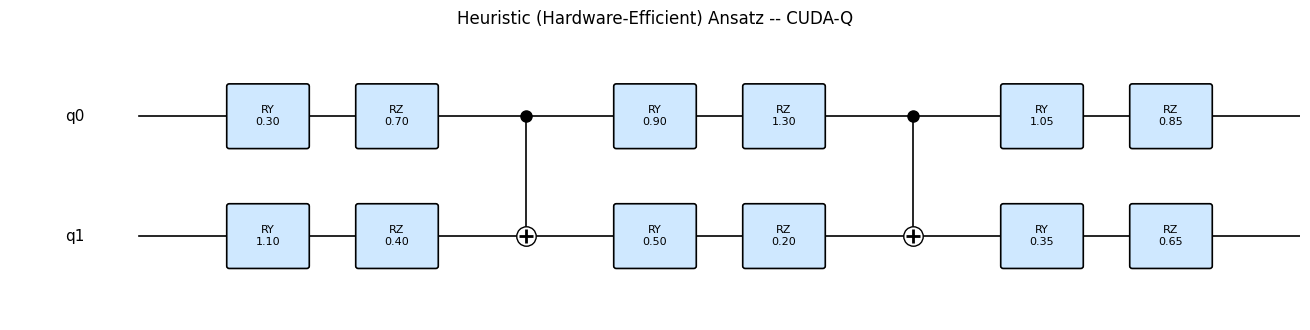

In [4]:
# Draw the circuit with matplotlib, styled to visually resemble the Qiskit diagram
# (wires, boxed gate labels, same qubit top-to-bottom order: q0 on top).

columns = [
    [("box", 0, f"RY\n{THETA[0]:.2f}"), ("box", 1, f"RY\n{THETA[2]:.2f}")],
    [("box", 0, f"RZ\n{THETA[1]:.2f}"), ("box", 1, f"RZ\n{THETA[3]:.2f}")],
    [("cnot", 0, 1)],
    [("box", 0, f"RY\n{THETA[4]:.2f}"), ("box", 1, f"RY\n{THETA[6]:.2f}")],
    [("box", 0, f"RZ\n{THETA[5]:.2f}"), ("box", 1, f"RZ\n{THETA[7]:.2f}")],
    [("cnot", 0, 1)],
    [("box", 0, f"RY\n{THETA[8]:.2f}"), ("box", 1, f"RY\n{THETA[10]:.2f}")],
    [("box", 0, f"RZ\n{THETA[9]:.2f}"), ("box", 1, f"RZ\n{THETA[11]:.2f}")],
]

fig, ax = plt.subplots(figsize=(1.4 * len(columns) + 2, 1.2 * N_QUBITS + 1))
y_of_q = {q: (N_QUBITS - 1 - q) for q in range(N_QUBITS)}
x_start, x_end = 0, len(columns) + 1

for q in range(N_QUBITS):
    y = y_of_q[q]
    ax.plot([x_start, x_end], [y, y], color="black", zorder=1, lw=1.2)
    ax.text(x_start - 0.5, y, f"q{q}", ha="center", va="center", fontsize=11)

box_w, box_h = 0.6, 0.5
for col_idx, col in enumerate(columns):
    x = col_idx + 1
    for item in col:
        if item[0] == "box":
            _, q, label = item
            y = y_of_q[q]
            rect = patches.FancyBboxPatch((x - box_w / 2, y - box_h / 2), box_w, box_h,
                                           boxstyle="round,pad=0.02",
                                           linewidth=1.2, edgecolor="black",
                                           facecolor="#cfe8ff", zorder=3)
            ax.add_patch(rect)
            ax.text(x, y, label, ha="center", va="center", fontsize=8, zorder=4)
        elif item[0] == "cnot":
            _, ctrl, tgt = item
            y_ctrl, y_tgt = y_of_q[ctrl], y_of_q[tgt]
            ax.plot([x, x], [min(y_ctrl, y_tgt), max(y_ctrl, y_tgt)], color="black", zorder=2, lw=1.2)
            ax.plot(x, y_ctrl, marker="o", color="black", markersize=8, zorder=4)
            ax.plot(x, y_tgt, marker="o", color="white", markeredgecolor="black", markersize=14, zorder=4)
            ax.plot(x, y_tgt, marker="+", color="black", markersize=10, zorder=5, mew=2)

ax.set_xlim(x_start - 1, x_end)
ax.set_ylim(-0.7, N_QUBITS - 0.3)
ax.axis("off")
ax.set_title("Heuristic (Hardware-Efficient) Ansatz -- CUDA-Q", fontsize=12)
plt.tight_layout()
plt.savefig("heuristic_ansatz_cudaq_circuit.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# Explicit matrix representation.
# Note: CUDA-Q does not expose a stable, general-purpose "circuit -> unitary matrix"
# operator-extraction API the way qiskit.quantum_info.Operator does (rule 4's
# "framework's own operator extraction where available" does not apply here). The
# cross-check for this notebook is therefore: build the SAME hand-derived NumPy matrix
# used in the Qiskit notebook, and separately verify it reproduces the statevector that
# CUDA-Q's own simulator returns (done in the next cell) -- i.e. cross-checked against
# CUDA-Q's own get_state() output rather than a second CUDA-Q-native matrix API.

def RY(t):
    c, s = np.cos(t / 2), np.sin(t / 2)
    return np.array([[c, -s], [s, c]], dtype=complex)

def RZ(t):
    return np.array([[np.exp(-1j * t / 2), 0], [0, np.exp(1j * t / 2)]], dtype=complex)

CNOT_01 = np.array([   # control=q0, target=q1, basis {|00>,|01>,|10>,|11>} = q1 q0 order
    [1, 0, 0, 0],
    [0, 0, 0, 1],
    [0, 0, 1, 0],
    [0, 1, 0, 0]
], dtype=complex)

def rot_block_matrix(t_q0_ry, t_q0_rz, t_q1_ry, t_q1_rz):
    U_q0 = RZ(t_q0_rz) @ RY(t_q0_ry)
    U_q1 = RZ(t_q1_rz) @ RY(t_q1_ry)
    return np.kron(U_q1, U_q0)   # q1 (MSB) kron q0 (LSB) -- same convention as Qiskit notebook

U_R0 = rot_block_matrix(THETA[0], THETA[1], THETA[2], THETA[3])
U_R1 = rot_block_matrix(THETA[4], THETA[5], THETA[6], THETA[7])
U_R2 = rot_block_matrix(THETA[8], THETA[9], THETA[10], THETA[11])
U_handbuilt = U_R2 @ CNOT_01 @ U_R1 @ CNOT_01 @ U_R0

print("Hand-built full unitary U (NumPy), basis {|00>,|01>,|10>,|11>} (Qiskit convention), rounded to 4 dp:")
print(np.round(U_handbuilt, 4))

Hand-built full unitary U (NumPy), basis {|00>,|01>,|10>,|11>} (Qiskit convention), rounded to 4 dp:
[[-0.4759-0.351j  -0.3881+0.0033j  0.0036+0.6696j  0.0214+0.2255j]
 [ 0.2684-0.0356j  0.2838+0.5798j -0.0286+0.4556j -0.4472-0.3187j]
 [ 0.098 -0.5096j -0.4503+0.0365j  0.4724-0.3374j -0.2689-0.3424j]
 [ 0.5207+0.1911j -0.4215+0.2255j  0.079 +0.0067j -0.1465+0.6604j]]


In [6]:
# Exact statevector cell: extract it, apply the bit-order correction, then the
# global-phase normalization, in that order, each in its own explicit step.

state = cudaq.get_state(ansatz, THETA)
raw_amps = np.array(state)   # index i uses CUDA-Q convention: q0 = MOST-significant bit

n = N_QUBITS
raw_labels = [format(i, f"0{n}b") for i in range(2 ** n)]   # these are "q0 q1" strings (q0 first/MSB)

# --- Bit-order correction (CUDA-Q only): reverse each label so q0 becomes the
#     rightmost character, matching Qiskit's convention. This is a relabeling of the
#     SAME amplitudes -- no physics changes, only which printed string each amplitude
#     is filed under.
reordered = {}
for i, raw_label in enumerate(raw_labels):
    qiskit_style_label = raw_label[::-1]        # "q0 q1" -> "q1 q0"
    reordered[qiskit_style_label] = raw_amps[i]

qiskit_style_labels_ascending = sorted(reordered.keys())
amps_reordered = np.array([reordered[lab] for lab in qiskit_style_labels_ascending])

# --- Global phase normalization: identical function/convention to the Qiskit notebook.
def normalize_global_phase(vec):
    for amp in vec:
        if abs(amp) > 1e-9:
            phase = np.angle(amp)
            return vec * np.exp(-1j * phase)
    return vec

amps_normalized = normalize_global_phase(amps_reordered)

print("Amplitudes (bit-order corrected, phase-normalized):")
for lab, amp in zip(qiskit_style_labels_ascending, amps_normalized):
    print(f"  |{lab}>: {amp:.6f}")

probs_statevector = {lab: float(abs(amp) ** 2) for lab, amp in zip(qiskit_style_labels_ascending, amps_normalized)}
probs_statevector = dict(sorted(probs_statevector.items()))
print("\nProbability dictionary (sorted by bitstring, Qiskit convention):")
print(probs_statevector)

Amplitudes (bit-order corrected, phase-normalized):
  |00>: 0.591331-0.000000j
  |01>: 0.223655+0.468285j
  |10>: -0.194904+0.187977j
  |11>: -0.532517+0.155299j

Probability dictionary (sorted by bitstring, Qiskit convention):
{'00': 0.3496723715344665, '01': 0.2693125334621995, '10': 0.07332289770218933, '11': 0.30769219730114455}


**Ordering-fix note:** CUDA-Q's `get_state()` indexes amplitudes with qubit 0 as the
most-significant (leftmost) bit -- the opposite of Qiskit. The cell above reverses each
raw `n`-bit label (`"q0 q1" -> "q1 q0"`) before doing anything else, so every amplitude
is filed under the same bitstring key Qiskit would use for the identical physical state.
Only *after* that relabeling is the global-phase normalization applied, using the exact
same function as the Qiskit notebook (first nonzero amplitude in ascending bitstring
order rotated to be real and positive).

In [7]:
# Measurement / sampling cell.
raw_counts = cudaq.sample(ansatz, THETA, shots_count=SHOTS)

# Reverse each sampled bitstring the same way as the statevector amplitudes above.
counts_reordered = {}
for raw_bits in raw_counts:
    qiskit_style_bits = raw_bits[::-1]
    counts_reordered[qiskit_style_bits] = counts_reordered.get(qiskit_style_bits, 0) + raw_counts.count(raw_bits)

probs_sampled = {lab: counts_reordered.get(lab, 0) / SHOTS for lab in qiskit_style_labels_ascending}
probs_sampled = dict(sorted(probs_sampled.items()))
print("Sampled probability dictionary (sorted by bitstring, Qiskit convention):")
print(probs_sampled)

Sampled probability dictionary (sorted by bitstring, Qiskit convention):
{'00': 0.3465, '01': 0.0708, '10': 0.2739, '11': 0.3088}


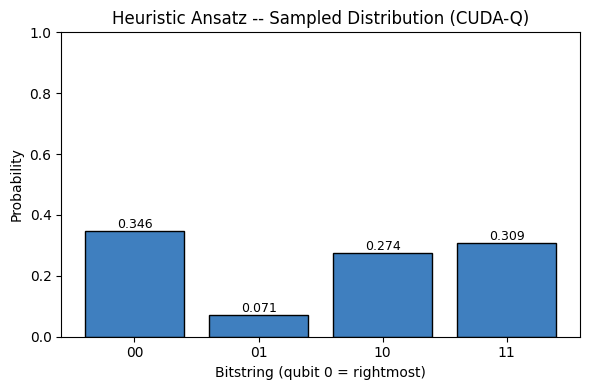

In [8]:
# Histogram cell -- matplotlib bar chart, same axis ranges/labels/style as the Qiskit notebook.
fig2, ax2 = plt.subplots(figsize=(6, 4))
sorted_labels = sorted(probs_sampled.keys())
values = [probs_sampled[l] for l in sorted_labels]
ax2.bar(sorted_labels, values, color="#3f7fbf", edgecolor="black")
ax2.set_xlabel("Bitstring (qubit 0 = rightmost)")
ax2.set_ylabel("Probability")
ax2.set_ylim(0, 1)
ax2.set_title("Heuristic Ansatz -- Sampled Distribution (CUDA-Q)")
for i, v in enumerate(values):
    ax2.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig("heuristic_ansatz_cudaq_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# Resource counts.
circuit_text = str(cudaq.draw(ansatz, THETA))
depth_estimate = circuit_text.count("\n")  # CUDA-Q has no direct .depth() API; count moments from the drawing as a proxy
gate_count = 12 * 2 + 2   # 12 single-qubit rotations (RY+RZ x 3 blocks x 2 qubits) + 2 CNOTs
print("Gate count (RY + RZ + CNOT):", gate_count)
print("Kernel qubit count:", N_QUBITS)

Gate count (RY + RZ + CNOT): 26
Kernel qubit count: 2


**Convention notes (plain text):**
- Bit ordering: CUDA-Q natively prints qubit 0 as the leftmost bit; **every bitstring
  above was reversed** (both the statevector amplitude labels and the sampled counts)
  before being reported, so that qubit 0 = rightmost, matching the Qiskit notebook.
- Global phase: after the bit-order fix, the statevector was rotated so the first basis
  state (in ascending bitstring order `'00' < '01' < '10' < '11'`) with nonzero amplitude
  has a real, positive coefficient -- identical convention to the Qiskit notebook.

In [10]:
# Final result dictionary.
CUDAQ_RESULT = probs_sampled
print("CUDAQ_RESULT =", CUDAQ_RESULT)

CUDAQ_RESULT = {'00': 0.3465, '01': 0.0708, '10': 0.2739, '11': 0.3088}


In [11]:
# Diff-check block (paste QISKIT_RESULT here from the Qiskit notebook's final cell,
# or run both under a shared driver -- left commented out since this notebook can't
# see the other kernel's variables).
#
# QISKIT_RESULT = {...}  # paste from the Qiskit notebook's final cell
#
# hand_computed_expected = {
#     '00': 0.349672, '01': 0.073323, '10': 0.269313, '11': 0.307692
# }  # re-derived by hand from the gate-by-gate unitary (see prompt notes)
#
# max_delta = max(abs(CUDAQ_RESULT[k] - QISKIT_RESULT[k]) for k in CUDAQ_RESULT)
# print("Max prob delta:", max_delta)
# assert max_delta < 1e-3, "CUDA-Q and Qiskit results disagree beyond tolerance!"